In [1]:
from finguard.data.loader import load_data

In [2]:
df = load_data("../data/raw/creditcard.csv")

Data loaded successfully. Shape: (284807, 31)


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df[["V1", "V2", "V3"]].describe()

,V1,V2,V3
count,2.848070e+05,2.848070e+05,2.848070e+05
mean,1.175161e-15,3.384974e-16,-1.379537e-15
std,1.958696e+00,1.651309e+00,1.516255e+00
min,-5.640751e+01,-7.271573e+01,-4.832559e+01
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01
50%,1.810880e-02,6.548556e-02,1.798463e-01
75%,1.315642e+00,8.037239e-01,1.027196e+00
max,2.454930e+00,2.205773e+01,9.382558e+00


## Class Distribution Analysis

In [6]:
print( f"Total number of transactions: {df.shape[0]}" )

Total number of transactions: 284807


In [16]:
print(df.loc[df["Class"] == 0].value_counts())


Time      V1          V2          V3         V4         V5         V6         V7         V8         V9         V10         V11        V12        V13        V14        V15        V16        V17        V18        V19        V20        V21        V22       V23        V24        V25        V26        V27        V28        Amount  Class
163152.0  -1.196037    1.585949    2.883976   3.378471   1.511706   3.717077   0.585362  -0.156001   0.122648   4.217934    1.385525  -0.709405  -0.256168  -1.564352   1.693218  -0.785210  -0.228008  -0.412833   0.234834   1.375790  -0.370294  0.524395  -0.355170  -0.869790  -0.133198   0.327804  -0.035702  -0.858197  7.56    0        18
          -1.203617    1.574009    2.889277   3.381404   1.538663   3.698747   0.560211  -0.150911   0.124136   4.220998    1.384569  -0.706897  -0.256274  -1.562583   1.692915  -0.787338  -0.226776  -0.412354   0.234322   1.385597  -0.366727  0.522223  -0.357329  -0.870174  -0.134166   0.327019  -0.042648  -0.855262  1.51  

In [22]:
legit_transactions = df.loc[df["Class"] == 0]
fraud_transactions = df.loc[df["Class"] == 1]
print("Number of legitimate transactions:", legit_transactions.shape[0])
print("Number of fraudulent transactions:", fraud_transactions.shape[0])
fraud_percentage = (fraud_transactions.shape[0] / df.shape[0]) * 100
print(f"Percentage of fraudulent transactions: {fraud_percentage:.4f}%")



Number of legitimate transactions: 284315
Number of fraudulent transactions: 492
Percentage of fraudulent transactions: 0.1727%


Dataset Imbalance detected

In [25]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


## 5. Transaction Amount Analysis

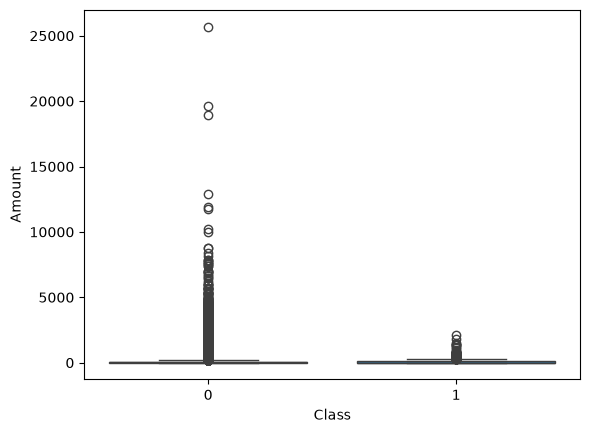

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="Class", y="Amount")
# plt.yscale("symlog")
plt.show()

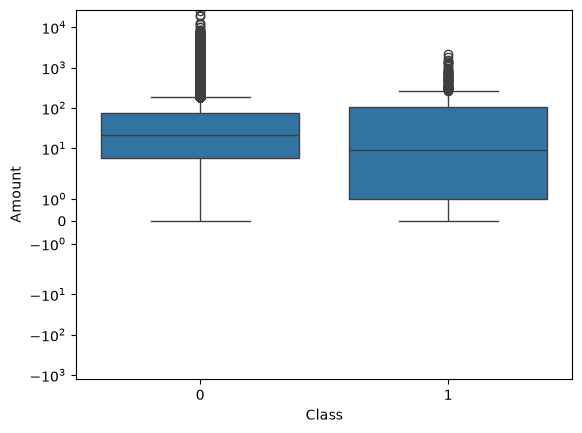

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="Class", y="Amount")
plt.yscale("symlog")
plt.show()